# Notebook de documentacion, tratamiento datos y entrenamiento


## Equipo
- Alumno 1 : Lucas Diaz Celauro
- Alumno 2 : Amanda Tardugno

## Configuración

In [1]:
# Bibliotecas, semilla y rutas que se usan en toda la notebook
import re
import sys
import random
import difflib
import unicodedata
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

RUTA_DATOS = Path("data")
RUTA_PINS = RUTA_DATOS / "105_classes_pins_dataset"
RUTA_LFW = RUTA_DATOS / "lfw"
RUTA_PARES = RUTA_DATOS / "raw" / "lfw_pairs"
RUTA_INTERMEDIOS = RUTA_DATOS / "intermedios"
RUTA_INTERMEDIOS.mkdir(parents=True, exist_ok=True)

COLORES = {"Pins": "#1f77b4", "LFW": "#d62728"}

## Inventario

In [2]:
def normalizar_nombre(nombre):
    """Nombre en minúsculas, sin acentos, signos ni guiones bajos, para comparar personas entre datasets."""
    nombre = unicodedata.normalize("NFKD", nombre.replace("_", " ")).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z ]", "", nombre.lower()).strip()

In [3]:
# Una fila por archivo (dataset, persona y ruta), ordenadas por nombre y con "/" para que el orden y las rutas no dependan del sistema operativo
por_nombre = lambda ruta: ruta.name
filas = [
    {"dataset": "Pins", "persona": carpeta.name.removeprefix("pins_"), "ruta": archivo.as_posix()}
    for carpeta in sorted(RUTA_PINS.iterdir(), key=por_nombre) for archivo in sorted(carpeta.iterdir(), key=por_nombre)
]
filas += [
    {"dataset": "LFW", "persona": carpeta.name, "ruta": archivo.as_posix()}
    for carpeta in sorted(RUTA_LFW.iterdir(), key=por_nombre) for archivo in sorted(carpeta.iterdir(), key=por_nombre)
]
imagenes = pd.DataFrame(filas)
imagenes["persona_norm"] = imagenes["persona"].map(normalizar_nombre)
imagenes["extension"] = imagenes["ruta"].str.rsplit(".", n=1).str[-1].str.lower()
imagenes.groupby("dataset", sort=False).agg(personas=("persona", "nunique"), archivos=("ruta", "size"), extensiones=("extension", "unique"))

,personas,archivos,extensiones
dataset,,,
Pins,105,17534,[jpg]
LFW,5749,13233,[jpg]


Pins trae 105 personas y 17.534 fotos; LFW, 5.749 personas y 13.233 fotos. Todos los archivos son `.jpg`.

In [4]:
# Fotos por persona en cada dataset
fotos_por_persona = imagenes.groupby(["dataset", "persona"], sort=False).size().rename("fotos").reset_index()
pd.DataFrame({
    dataset: {"personas": len(f), "mínimo": f.min(), "mediana": f.median(), "media": round(f.mean(), 1), "máximo": f.max()}
    for dataset, f in fotos_por_persona.groupby("dataset", sort=False)["fotos"]
}).T

,personas,mínimo,mediana,media,máximo
Pins,105.0,86.0,169.0,167.0,237.0
LFW,5749.0,1.0,1.0,2.3,530.0


In [5]:
# Personas de LFW agrupadas por cantidad de fotos
fotos_lfw = fotos_por_persona.query("dataset == 'LFW'").set_index("persona")["fotos"]
grupo_lfw = pd.cut(fotos_lfw, bins=[0, 1, 9, 19, np.inf], labels=["1 foto", "2–9", "10–19", "20 o más"])
tabla_grupos = fotos_lfw.groupby(grupo_lfw, observed=True).agg(personas="size", fotos="sum")
tabla_grupos["% de las fotos"] = (100 * tabla_grupos["fotos"] / tabla_grupos["fotos"].sum()).round(1)
tabla_grupos

,personas,fotos,% de las fotos
fotos,,,
1 foto,4069,4069,30.7
2–9,1522,4840,36.6
10–19,96,1301,9.8
20 o más,62,3023,22.8


In [6]:
# Peso de las cinco personas con más fotos en LFW
top_lfw = fotos_lfw.nlargest(5)
print(top_lfw.to_string())
print(f"Suman {top_lfw.sum()} fotos  |  {100 * top_lfw.sum() / fotos_lfw.sum():.1f}% de LFW  |  {100 * top_lfw.sum() / fotos_lfw[fotos_lfw >= 20].sum():.1f}% del grupo con 20 o más")

persona
George_W_Bush        530
Colin_Powell         236
Tony_Blair           144
Donald_Rumsfeld      121
Gerhard_Schroeder    109
Suman 1140 fotos  |  8.6% de LFW  |  37.7% del grupo con 20 o más


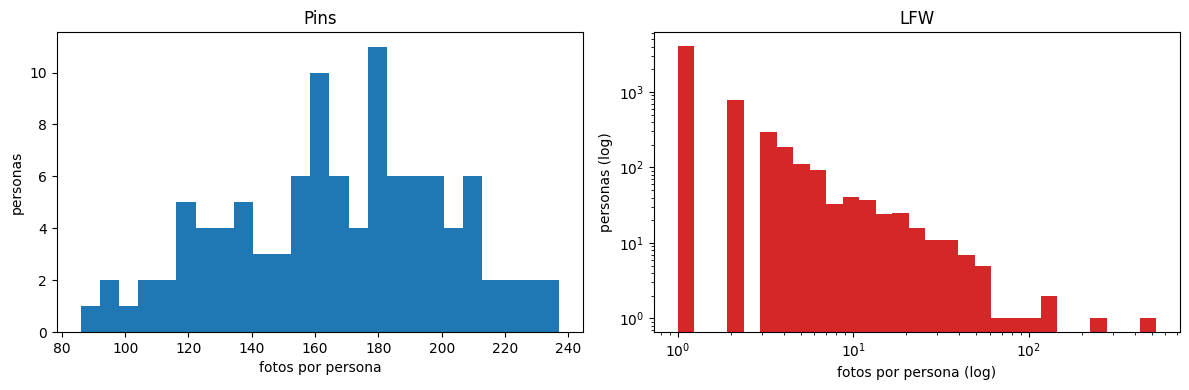

In [7]:
# Distribución de fotos por persona (LFW en escala logarítmica por su cola larga)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
f_pins = fotos_por_persona.query("dataset == 'Pins'")["fotos"]
ejes[0].hist(f_pins, bins=25, color=COLORES["Pins"])
ejes[0].set(title="Pins", xlabel="fotos por persona", ylabel="personas")
ejes[1].hist(fotos_lfw, bins=np.logspace(0, np.log10(fotos_lfw.max() + 1), 30), color=COLORES["LFW"])
ejes[1].set(title="LFW", xlabel="fotos por persona (log)", ylabel="personas (log)", xscale="log", yscale="log")
plt.tight_layout()
plt.show()

*Figura 1. Cantidad de fotos por persona en Pins y en LFW (en LFW, los dos ejes en escala logarítmica).*

Los dos datasets tienen estructuras opuestas (Figura 1). Pins está casi balanceado: cada persona tiene entre 86 y 237 fotos, con una mediana de 169, así que el desbalance de clases no es un problema para entrenar con él. LFW tiene una cola larga: la mediana es de 1 foto por persona, 4.069 personas (el 70,8%) tienen una sola, y las cinco con más fotos suman 1.140, el 37,7% del grupo con 20 o más. George W. Bush tiene 530 fotos.

## Elección de los datasets

El dataset cumple dos funciones con requisitos opuestos. Entrenar la CNN custom necesita **muchas fotos por persona**, porque la red aprende a separar identidades viendo muchas variantes de cada una. Evaluar los modelos necesita **muchas personas que la CNN no vio**, porque ese es el escenario de la app (se registra gente nueva) y porque de ahí sale el umbral que va a `SIMILARITY_THRESHOLD`. Ninguno de los dos datasets cubre ambas cosas por separado:

- Con Pins solo, cada persona que va a evaluación es una menos para entrenar. Con un reparto de 70, 15 y 20 personas, el test tendría 190 combinaciones de personas distintas para los pares negativos, y el umbral saldría de 15 personas.
- Con LFW solo, la CNN entrenaría con 62 personas, y 5 de ellas aportan el 37,7% de las fotos.

Por eso se usan los dos, cada uno para lo que tiene:

| Uso | Dataset |
|---|---|
| Entrenar la CNN y validarla (curvas, early stopping) | Pins: 90 personas sorteadas, con fotos distintas en train y validación |
| Test open-set del mismo dominio que el entrenamiento | Pins: las otras 15 personas |
| Calibrar el umbral, test open-set, desconocidos y pares oficiales | LFW, sin las personas que también están en Pins |

Las 15 personas de test de Pins permiten separar dos causas que, de otro modo, se confunden: si la CNN rinde peor en LFW que en el test de Pins, la diferencia se debe al cambio de dominio y no a que el modelo no generalice a personas nuevas. Que los dos datasets son dominios distintos es, por ahora, una hipótesis que las secciones de formato, resolución e iluminación ponen a prueba.

Los dos pasan por el mismo pipeline de la app (`FaceService`), así que el formato queda unificado en caras alineadas de 112×112. El enunciado ofrece otras opciones: CelebA y CASIA-WebFace son demasiado grandes para procesar en CPU en el tiempo del trabajo, y de FaceScrub, VGGFace2 y DigiFace el propio enunciado advierte que hay que verificar su disponibilidad y su licencia.

Hay una limitación que afecta a cualquier dataset de celebridades: el modelo preentrenado (ArcFace, entrenado con WebFace600K, fotos de famosos tomadas de internet) puede haber visto a algunas de estas personas. Si pasó, el preentrenado tiene una ventaja en la comparación que la CNN no tiene.

## Personas en los dos datasets

In [8]:
# Personas cuyo nombre normalizado está en los dos datasets
nombres = imagenes.groupby("dataset")["persona_norm"].unique()
repetidas_norm = sorted(set(nombres["Pins"]) & set(nombres["LFW"]))
conteo = imagenes[imagenes["persona_norm"].isin(repetidas_norm)].pivot_table(index="persona_norm", columns="dataset", values="ruta", aggfunc="size")
conteo = conteo[["Pins", "LFW"]].rename(columns={"Pins": "fotos en Pins", "LFW": "fotos en LFW"})
print(f"Personas repetidas: {len(conteo)}  |  fotos de LFW afectadas: {conteo['fotos en LFW'].sum()}")
conteo

Personas repetidas: 15  |  fotos de LFW afectadas: 82


dataset,fotos en Pins,fotos en LFW
persona_norm,,
adriana lima,213,1
avril lavigne,162,1
ben affleck,126,7
bill gates,122,17
christian bale,154,1
dwayne johnson,141,2
emma watson,211,5
gwyneth paltrow,187,6
johnny depp,182,2


Quince personas están en los dos datasets, y suman 82 fotos en LFW. Se sacan de LFW y no de Pins: Pins es el único dataset con fotos suficientes para entrenar, y perder 15 de sus 105 personas (el 14,3%) pesa mucho más que perder 82 de las 13.233 fotos de LFW (el 0,62%). Se sacan las 15 aunque alguna caiga en el test de Pins, donde no habría fuga, para que los dos datasets tengan personas disjuntas y las dos evaluaciones sean independientes.

In [9]:
# Coincidencias aproximadas de nombre (ratio >= 0,85) que no son exactas, por si hay variantes de escritura
lfw_norm = list(nombres["LFW"])
aproximadas = [
    {"Pins": nombre, "LFW": candidato, "ratio": round(difflib.SequenceMatcher(None, nombre, candidato).ratio(), 2)}
    for nombre in sorted(nombres["Pins"])
    for candidato in difflib.get_close_matches(nombre, lfw_norm, n=3, cutoff=0.85)
    if candidato != nombre
]
pd.DataFrame(aproximadas)

,Pins,LFW,ratio
0,eliza taylor,elizabeth taylor,0.86
1,elizabeth lail,elizabeth hill,0.86
2,elizabeth olsen,elizabeth dole,0.90
3,richard harmon,richard hamilton,0.87


Las cuatro coincidencias aproximadas son personas distintas que comparten el nombre de pila, así que el cruce exacto alcanza. El cruce por nombre no detecta a una misma persona escrita de dos formas muy distintas (por ejemplo, un apodo). Eso se controla de nuevo con los embeddings, en la verificación de fuga entre conjuntos.

## Integridad, formato y canales

In [10]:
def describir_imagen(ruta):
    """Si la imagen abre, su tamaño, si es gris en la práctica, y su brillo y contraste."""
    img = cv2.imread(ruta)
    if img is None:
        return {"abre": False}
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    canales = img.astype(np.int16)
    dif_canales = max(np.abs(canales[..., 0] - canales[..., 1]).mean(), np.abs(canales[..., 1] - canales[..., 2]).mean())
    return {
        "abre": True, "alto": img.shape[0], "ancho": img.shape[1],
        "es_gris": bool(dif_canales < 2), "brillo": float(gris.mean()), "contraste": float(gris.std()),
    }

In [11]:
# Recorre todos los archivos una sola vez y guarda el resultado en disco, porque leer más de 30.000 fotos tarda
ruta_inventario = RUTA_INTERMEDIOS / "inventario.csv"
if ruta_inventario.exists():
    inventario = pd.read_csv(ruta_inventario)
    assert inventario["ruta"].equals(imagenes["ruta"]), "inventario.csv no corresponde, fila a fila, a los archivos de data/"
else:
    inventario = pd.concat([imagenes, pd.DataFrame([describir_imagen(r) for r in imagenes["ruta"]])], axis=1)
    inventario.to_csv(ruta_inventario, index=False)
inventario.groupby("dataset", sort=False).agg(
    archivos=("ruta", "size"), no_abren=("abre", lambda s: int((~s.astype(bool)).sum())),
    en_gris=("es_gris", "sum"), alto_min=("alto", "min"), alto_max=("alto", "max"), ancho_min=("ancho", "min"), ancho_max=("ancho", "max"),
)

,archivos,no_abren,en_gris,alto_min,alto_max,ancho_min,ancho_max
dataset,,,,,,,
Pins,17534,0,1261,82,802,80,564
LFW,13233,0,45,250,250,250,250


Ningún archivo falla al abrirse. Todos tienen tres canales, pero 1.261 fotos de Pins (el 7,2%) son en la práctica escala de grises (los tres canales iguales), contra 45 en LFW (el 0,3%). Es la primera diferencia de dominio medida: una CNN entrenada con Pins ve fotos en gris con frecuencia, y en LFW casi no aparecen.

## Resoluciones

LFW: tamaños distintos = [[250, 250]]
Pins: lado menor < 112 px: 2626 fotos (15.0%)  |  mediana del lado menor: 175 px


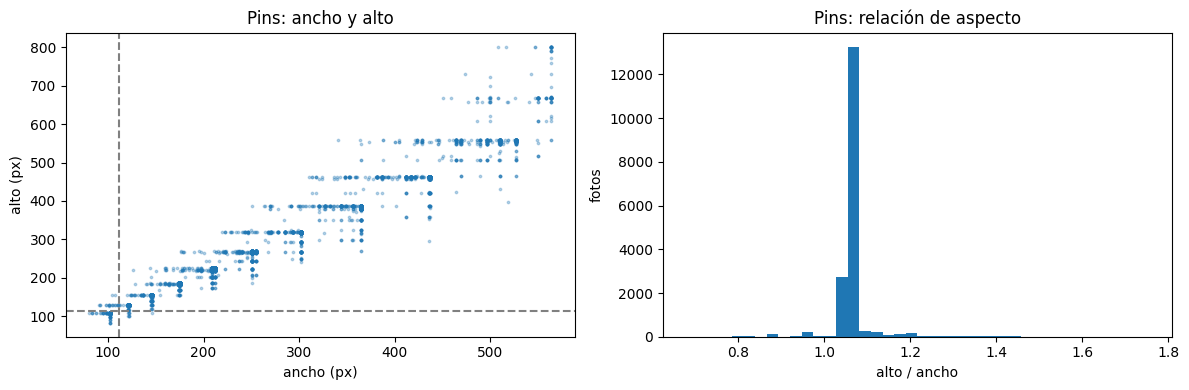

In [12]:
# Tamaño de las fotos de Pins y fotos cuyo lado menor no llega a FACE_SIZE
FACE_SIZE = 112
pins_inv = inventario.query("dataset == 'Pins'")
lado_menor = pins_inv[["alto", "ancho"]].min(axis=1)
print(f"LFW: tamaños distintos = {inventario.query('dataset == \"LFW\"')[['alto', 'ancho']].drop_duplicates().values.tolist()}")
print(f"Pins: lado menor < {FACE_SIZE} px: {(lado_menor < FACE_SIZE).sum()} fotos ({100 * (lado_menor < FACE_SIZE).mean():.1f}%)  |  mediana del lado menor: {lado_menor.median():.0f} px")
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].scatter(pins_inv["ancho"], pins_inv["alto"], s=3, alpha=0.3, color=COLORES["Pins"])
ejes[0].axhline(FACE_SIZE, color="gray", ls="--"); ejes[0].axvline(FACE_SIZE, color="gray", ls="--")
ejes[0].set(title="Pins: ancho y alto", xlabel="ancho (px)", ylabel="alto (px)")
ejes[1].hist(pins_inv["alto"] / pins_inv["ancho"], bins=40, color=COLORES["Pins"])
ejes[1].set(title="Pins: relación de aspecto", xlabel="alto / ancho", ylabel="fotos")
plt.tight_layout()
plt.show()

*Figura 2. Ancho y alto de las fotos de Pins (las líneas marcan 112 px) y su relación de aspecto.*

LFW es homogéneo: todas las fotos miden 250×250. Pins varía entre 80 y 802 px de lado, pero con la relación de aspecto concentrada cerca de 1,07 (Figura 2): son recortes de la cara hechos de antemano, de tamaño variable. El 15,0% (2.626 fotos) tiene el lado menor por debajo de 112 px, así que su cara alineada va a salir de ampliar la imagen. Si eso degrada demasiado la calidad, va a aparecer en el filtro de tamaño mínimo de la cara.

## Iluminación y contraste

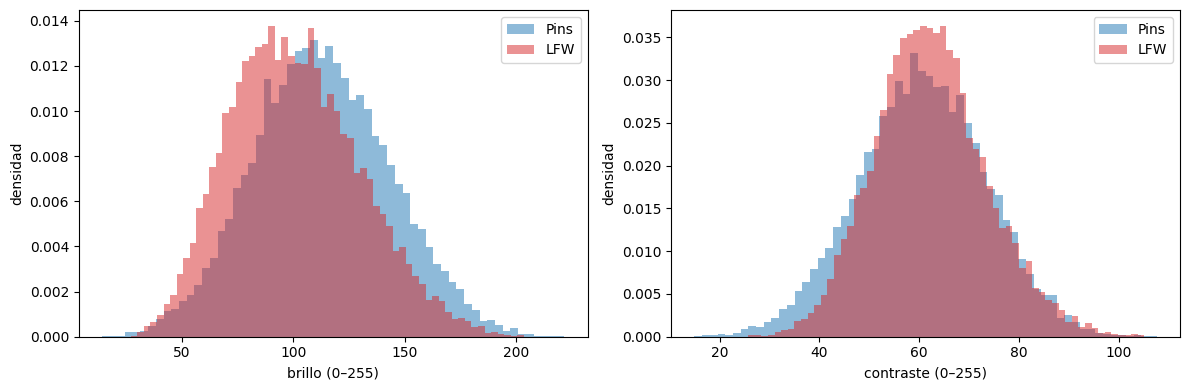

brillo                            contraste                         
           min   25%    50%    75%    max       min   25%   50%   75%    max
dataset                                                                     
Pins      14.0  91.6  112.0  133.9  221.8      15.0  52.1  60.7  69.4  107.6
LFW       27.0  79.5   98.7  120.0  203.6      25.8  54.7  61.8  69.2  105.1

In [13]:
# Brillo (media de gris) y contraste (desvío de gris) por dataset
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for eje, columna in zip(ejes, ["brillo", "contraste"]):
    for dataset in ["Pins", "LFW"]:
        eje.hist(inventario.query("dataset == @dataset")[columna], bins=60, density=True, alpha=0.5, color=COLORES[dataset], label=dataset)
    eje.set(xlabel=f"{columna} (0–255)", ylabel="densidad"); eje.legend()
plt.tight_layout()
plt.show()
inventario.groupby("dataset", sort=False)[["brillo", "contraste"]].describe().loc[:, (slice(None), ["min", "25%", "50%", "75%", "max"])].round(1)

*Figura 3. Brillo y contraste (media y desvío de la imagen en gris) de todas las fotos de cada dataset.*

Pins es más brillante que LFW: la mediana del brillo es 112,0 contra 98,7 (Figura 3). El contraste es parecido (60,7 contra 61,8). Es otra diferencia de dominio, pero moderada: las dos distribuciones se superponen en la mayor parte del rango. Los extremos (brillo mínimo de 14,0 en Pins) se revisan en el control de calidad.

## Muestra visual

In [14]:
def grilla(rutas, filas, columnas, titulos=None, lado=112):
    """Muestra las imágenes en una grilla, redimensionadas a lado × lado."""
    fig, ejes = plt.subplots(filas, columnas, figsize=(columnas * 1.6, filas * 1.75))
    for i, eje in enumerate(np.ravel(ejes)):
        eje.axis("off")
        if i < len(rutas):
            img = rutas[i] if isinstance(rutas[i], np.ndarray) else cv2.imread(str(rutas[i]))
            eje.imshow(cv2.cvtColor(cv2.resize(img, (lado, lado)), cv2.COLOR_BGR2RGB))
            if titulos is not None:
                eje.set_title(titulos[i], fontsize=7)
    plt.tight_layout()
    plt.show()

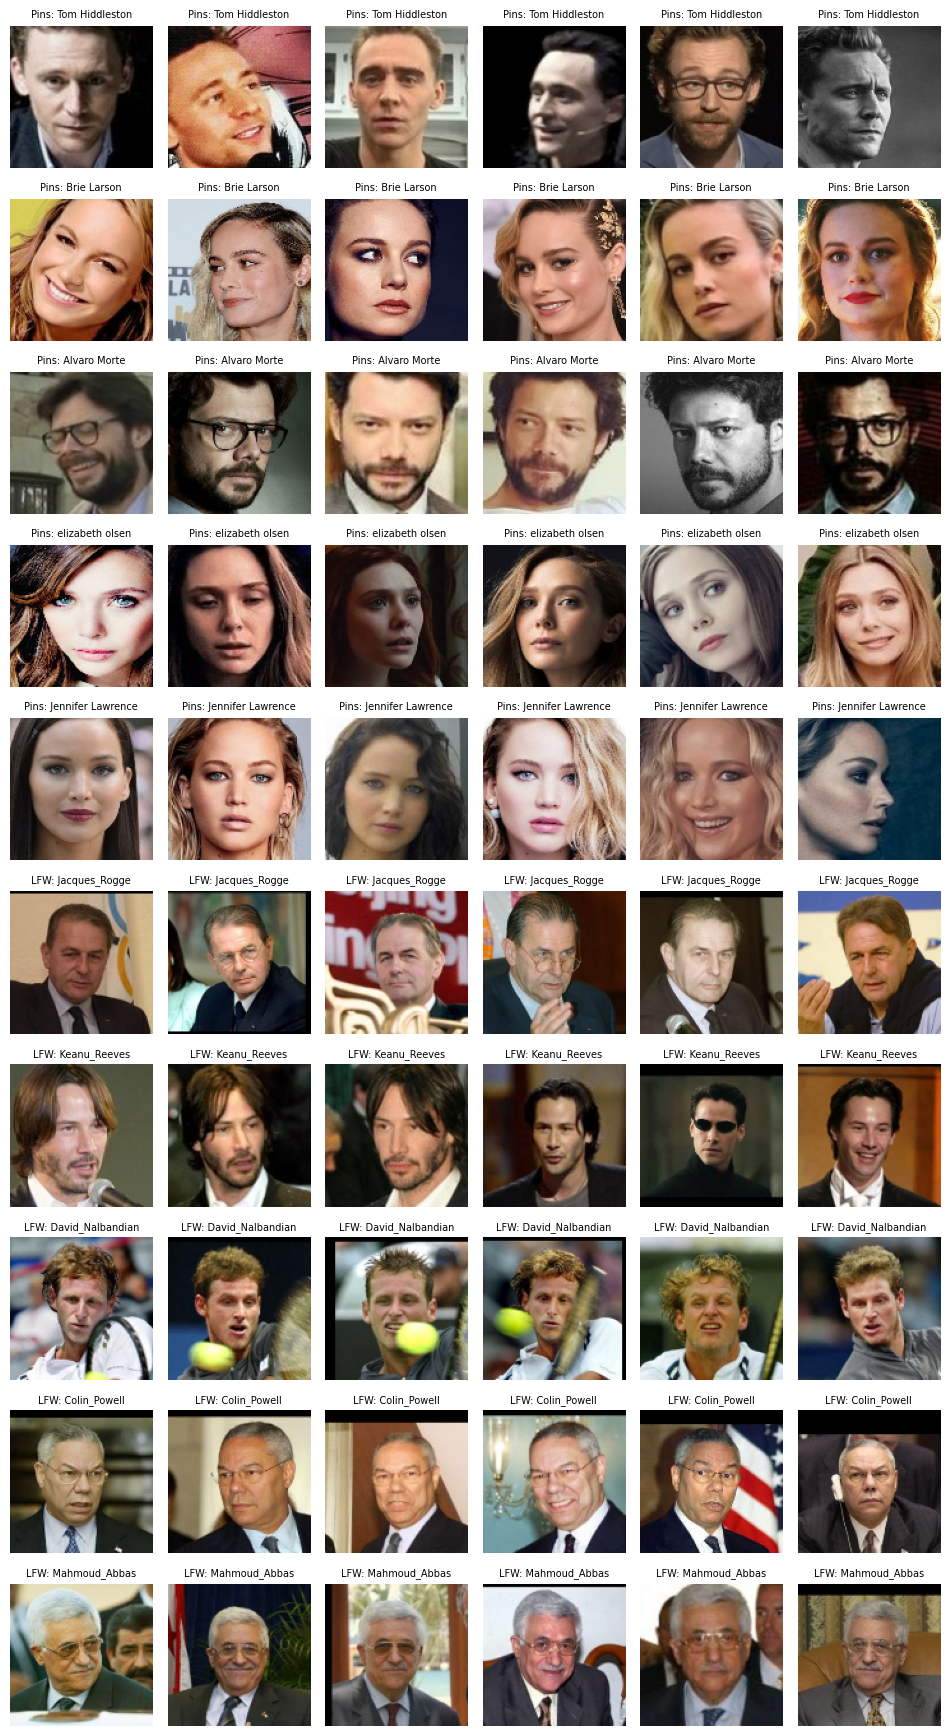

In [15]:
# Seis fotos al azar de cinco personas de cada dataset (en LFW, de las que tienen 10 o más)
rng = random.Random(SEMILLA)
rutas, titulos = [], []
for dataset, candidatas in [("Pins", sorted(fotos_por_persona.query("dataset == 'Pins'")["persona"])), ("LFW", sorted(fotos_lfw[fotos_lfw >= 10].index))]:
    for persona in rng.sample(candidatas, 5):
        fotos = sorted(imagenes.query("dataset == @dataset and persona == @persona")["ruta"])
        for ruta in rng.sample(fotos, 6):
            rutas.append(ruta); titulos.append(f"{dataset}: {persona[:18]}")
grilla(rutas, 10, 6, titulos)

*Figura 4. Seis fotos al azar de cinco personas de Pins (arriba) y de cinco personas de LFW con 10 o más fotos (abajo).*

La Figura 4 muestra la diferencia de dominio más importante, que no se ve en los números anteriores. En Pins la cara ocupa casi toda la foto, con mucha variación de pose (perfiles), expresión, maquillaje e iluminación, y con fotos en gris. En LFW la cara es más chica y está centrada, con mucho contexto: torso, fondo y, a veces, **otras caras** (la primera foto de Mahmoud Abbas). Varias fotos de LFW tienen además bandas negras en los bordes. Las oclusiones aparecen en los dos: anteojos de ver y de sol, una pelota de tenis y manos. Que haya otras caras en las fotos de LFW anticipa el criterio de "más de un rostro" del control de calidad: en LFW, descartar esas fotos perdería imágenes buenas, y lo correcto es quedarse con la cara principal.

## Detección y alineación

Las caras se detectan, se alinean y se convierten en embeddings con el mismo `FaceService` de la app (`src/lib/services/face_service.py`) y con los parámetros de `.env.local.example`. Así, el pipeline de la notebook es el de la app por construcción, y no una copia que se pueda desincronizar: SCRFD (`det_10g.onnx`) da las cajas y los cinco puntos; una segunda detección, sobre un recorte con margen alrededor de la caja, afina los puntos; `norm_crop` lleva la cara a la plantilla de ArcFace en 112×112; y `w600k_r50.onnx` calcula el embedding, que se normaliza con L2. Esos embeddings son los del Modelo B de la notebook 2, así que se calculan una sola vez, acá. La elección de SCRFD frente a otros detectores se compara con datos más adelante.

La app crea las sesiones de ONNX Runtime sin indicar proveedores y prepara el detector con `ctx_id=-1`, así que corre en CPU. Para procesar más de 30.000 fotos se reemplazan las dos sesiones por otras sobre los mismos archivos `.onnx`, pero en la GPU. El código de `FaceService` no cambia.

In [16]:
# FaceService de la app, armado con los parámetros de .env.local.example
import io
import json
import time
import logging
import warnings
import contextlib

import torch
import onnxruntime as ort
from dotenv import dotenv_values
from insightface.model_zoo.retinaface import RetinaFace
from insightface.utils.face_align import arcface_dst

sys.path.insert(0, "src")
from lib.services.face_service import FaceService
from lib.storage.embedding_store import EmbeddingStore

warnings.filterwarnings("ignore", message="`estimate` is deprecated")
logging.getLogger("lib.services.face_service").setLevel(logging.ERROR)

CONFIG_APP = dotenv_values(".env.local.example")
RUTA_MODELOS = Path(CONFIG_APP["MODEL_PATH"])
EMBEDDING_DIM = int(CONFIG_APP["EMBEDDING_DIM"])
with contextlib.redirect_stdout(io.StringIO()):
    servicio = FaceService(
        store=EmbeddingStore(RUTA_INTERMEDIOS / "servicio" / "embeddings.json"),
        similarity_metric=CONFIG_APP["SIMILARITY_METRIC"],
        similarity_threshold=float(CONFIG_APP["SIMILARITY_THRESHOLD"]),
        face_size=int(CONFIG_APP["FACE_SIZE"]),
        model_path=RUTA_MODELOS / CONFIG_APP["MODEL_NAME"],
        output_path=RUTA_INTERMEDIOS / "servicio",
        detector_path=RUTA_MODELOS / CONFIG_APP["DETECTOR_MODEL_NAME"],
        det_score_threshold=float(CONFIG_APP["DET_SCORE_THRESHOLD"]),
        det_input_size=int(CONFIG_APP["DET_INPUT_SIZE"]),
        min_face_size=int(CONFIG_APP["MIN_FACE_SIZE"]),
        align_margin=float(CONFIG_APP["ALIGN_MARGIN"]),
    )
proveedores_app = {"reconocedor": servicio.model.get_providers()[0], "detector": servicio.detector.session.get_providers()[0]}
{clave: CONFIG_APP[clave] for clave in ["MODEL_NAME", "DETECTOR_MODEL_NAME", "DET_SCORE_THRESHOLD", "DET_INPUT_SIZE", "MIN_FACE_SIZE", "ALIGN_MARGIN", "FACE_SIZE", "EMBEDDING_DIM"]}

C:\Users\lucas\OneDrive\Documents\Académicas\Computer_Vision\tuia-face-recognition-app\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'MODEL_NAME': 'w600k_r50.onnx',
 'DETECTOR_MODEL_NAME': 'det_10g.onnx',
 'DET_SCORE_THRESHOLD': '0.5',
 'DET_INPUT_SIZE': '640',
 'MIN_FACE_SIZE': '20',
 'ALIGN_MARGIN': '0.5',
 'FACE_SIZE': '112',
 'EMBEDDING_DIM': '512'}

In [17]:
# Las mismas dos redes en sesiones nuevas sobre la GPU, con el tamaño de entrada y el umbral que ya tiene el servicio
PROVEEDORES = ["CUDAExecutionProvider", "CPUExecutionProvider"]
ruta_detector = str(RUTA_MODELOS / CONFIG_APP["DETECTOR_MODEL_NAME"])
servicio.model = ort.InferenceSession(str(RUTA_MODELOS / CONFIG_APP["MODEL_NAME"]), providers=PROVEEDORES)
servicio.detector = RetinaFace(ruta_detector, session=ort.InferenceSession(ruta_detector, providers=PROVEEDORES))
servicio.detector.prepare(ctx_id=0, input_size=(servicio.det_input_size, servicio.det_input_size), det_thresh=servicio.det_score_threshold)
print(f"GPU: {torch.cuda.get_device_name(0)}  |  onnxruntime {ort.__version__}")
pd.DataFrame({
    "como la crea la app": proveedores_app,
    "en esta notebook": {"reconocedor": servicio.model.get_providers()[0], "detector": servicio.detector.session.get_providers()[0]},
})

GPU: NVIDIA GeForce RTX 3060 Laptop GPU  |  onnxruntime 1.24.4


,como la crea la app,en esta notebook
reconocedor,CPUExecutionProvider,CUDAExecutionProvider
detector,CPUExecutionProvider,CUDAExecutionProvider


In [18]:
BORDE = 0.25


def agregar_borde(img, tipo=cv2.BORDER_REFLECT_101):
    """Agrega un borde de BORDE veces el lado mayor por cada lado y devuelve la imagen y el ancho del borde en px."""
    p = int(BORDE * max(img.shape[:2]))
    return cv2.copyMakeBorder(img, p, p, p, p, tipo), p


def mas_centrada(cajas, alto, ancho):
    """La caja cuyo centro está más cerca del centro de la imagen."""
    return min(cajas, key=lambda c: (c[0] + c[2] - ancho) ** 2 + (c[1] + c[3] - alto) ** 2)


def mas_grande(cajas, alto, ancho):
    """La caja de mayor área."""
    return max(cajas, key=lambda c: (c[2] - c[0]) * (c[3] - c[1]))

Antes de procesar todo, se comprueba que la GPU dé lo mismo que la CPU. La referencia son 50 fotos fijas (25 de cada dataset) que se procesaron con el `FaceService` de la app, sin cambios y en CPU, en otra computadora. Los criterios se fijaron antes de correr en la GPU: la misma cantidad de caras en las 50, cajas que no difieran en más de 2 px y un coseno de al menos 0,999 entre los embeddings.

In [19]:
# Si la GPU da lo mismo que la CPU, las 50 fotos de referencia tienen las mismas caras, cajas a 2 px o menos y un coseno de 0,999 o más
referencia = pd.read_csv(RUTA_DATOS / "referencia_cpu" / "referencia_cpu_50.csv")
emb_referencia = np.load(RUTA_DATOS / "referencia_cpu" / "referencia_cpu_50_embeddings.npy")
filas_ref = []
for i, fila in referencia.iterrows():
    con_borde, _ = agregar_borde(cv2.imread(fila["ruta"]))
    cajas = servicio.detect_faces(con_borde)
    emb = np.array(servicio.extract_embedding_from_face(servicio.align_face(con_borde, cajas[0])))
    filas_ref.append({
        "caras_iguales": len(cajas) == fila["n_caras"],
        "dif_caja": np.abs(np.array(cajas[0]) - fila[["x1", "y1", "x2", "y2"]].to_numpy(float)).max(),
        "coseno": float(emb @ emb_referencia[i]),
    })
filas_ref = pd.DataFrame(filas_ref)
pd.DataFrame({
    "criterio": ["iguales en las 50", "2 o menos", "0,999 o más"],
    "GPU contra CPU": [f"{filas_ref['caras_iguales'].sum()} de {len(filas_ref)}", f"{filas_ref['dif_caja'].max():.0f}", f"{filas_ref['coseno'].min():.6f}"],
}, index=["cantidad de caras", "diferencia máxima de caja (px)", "coseno mínimo"])

,criterio,GPU contra CPU
cantidad de caras,iguales en las 50,50 de 50
diferencia máxima de caja (px),2 o menos,1
coseno mínimo,"0,999 o más",0.999895


La GPU cumple los tres criterios: las 50 fotos tienen la misma cantidad de caras, las cajas difieren como máximo en 1 px y el coseno mínimo es 0,999895. Son diferencias numéricas que no cambian ninguna decisión, así que todo lo que sigue se calcula en la GPU.

### Borde antes de detectar

SCRFD necesita contexto alrededor de la cara: con una cara que ocupa casi toda la imagen, no detecta nada. Las fotos de Pins son recortes de la cara (Figuras 2 y 4), así que la hipótesis es que, sin un borde, en Pins se pierde la mayoría de las caras, y que en LFW, donde la cara es chica y está centrada, el borde no cambia la detección. Se prueba con una muestra fija de 300 fotos por dataset, detectando con y sin un borde reflejado del 25% del lado mayor por lado. En LFW, además, se compara la caja más centrada de las dos detecciones (IoU).

In [20]:
# Caras detectadas con y sin borde en una muestra fija de 300 fotos por dataset, y caja de la cara principal en cada caso
muestra_borde = imagenes.groupby("dataset", sort=False).sample(300, random_state=SEMILLA)
filas_borde = []
for fila in muestra_borde.itertuples():
    img = cv2.imread(fila.ruta)
    alto, ancho = img.shape[:2]
    con_borde, p = agregar_borde(img)
    sin = servicio.detect_faces(img)
    con = [(x1 - p, y1 - p, x2 - p, y2 - p) for x1, y1, x2, y2 in servicio.detect_faces(con_borde)]
    principal = mas_centrada(con, alto, ancho) if con else None
    filas_borde.append({
        "dataset": fila.dataset, "ruta": fila.ruta, "caras_sin": len(sin), "caras_con": len(con),
        "iou": servicio._iou(np.array(mas_centrada(sin, alto, ancho)), np.array(principal)) if sin and con else np.nan,
        "area_cara": (principal[2] - principal[0]) * (principal[3] - principal[1]) / (alto * ancho) if con else np.nan,
    })
filas_borde = pd.DataFrame(filas_borde)
categoria = lambda n: np.select([n == 0, n == 1], ["0 caras", "1 cara"], "más de 1")
pd.concat({
    "sin borde": pd.crosstab(filas_borde["dataset"], categoria(filas_borde["caras_sin"]), colnames=[None]),
    "con borde": pd.crosstab(filas_borde["dataset"], categoria(filas_borde["caras_con"]), colnames=[None]),
}, axis=1).fillna(0).astype(int).loc[["Pins", "LFW"]]

sin borde                 con borde                
          0 caras 1 cara más de 1   0 caras 1 cara más de 1
dataset                                                    
Pins          271     29        0         1    295        4
LFW             1    246       53         0    234       66

In [21]:
# En LFW, cuánto se mueve la caja principal al agregar el borde, y qué parte de la foto ocupa la cara en cada dataset
iou_lfw = filas_borde.query("dataset == 'LFW'")["iou"].dropna()
print(f"LFW: IoU entre la cara principal sin borde y con borde: mediana {iou_lfw.median():.3f}, mínimo {iou_lfw.min():.3f}, {(iou_lfw >= 0.9).mean():.1%} con IoU >= 0,9 ({len(iou_lfw)} fotos)")
filas_borde.groupby("dataset", sort=False)["area_cara"].median().rename("mediana de la fracción de la foto que ocupa la cara").round(3).to_frame()

LFW: IoU entre la cara principal sin borde y con borde: mediana 0.967, mínimo 0.903, 100.0% con IoU >= 0,9 (299 fotos)


,mediana de la fracción de la foto que ocupa la cara
dataset,
Pins,0.528
LFW,0.192


La hipótesis se confirma. Sin borde, en Pins no se detecta ninguna cara en 271 de las 300 fotos (el 90%); con el borde, solo en 1. En LFW la detección casi no cambia: 299 de las 300 fotos tienen cara en los dos casos, y la cara principal es la misma (IoU mediano de 0,967 y mínimo de 0,903 contra la caja sin borde). La diferencia está en cuánto ocupa la cara: la mediana es el 52,8% de la foto en Pins y el 19,2% en LFW.

El borde también agrega caras: con borde, las fotos con más de una cara pasan de 0 a 4 en Pins y de 53 a 66 en LFW. Eso se mide con todas las fotos más abajo.

El borde también tiene un tipo. Un borde constante (negro) es el más simple, pero `norm_crop` rota la imagen para alinearla, y en una cara inclinada que llega hasta el borde de la foto eso puede meter el negro adentro de la cara alineada. Un borde replicado repite la última fila de píxeles, y uno reflejado espeja la imagen. Se comparan en las cuatro caras más inclinadas de la muestra de Pins, que son las que más rota la alineación.

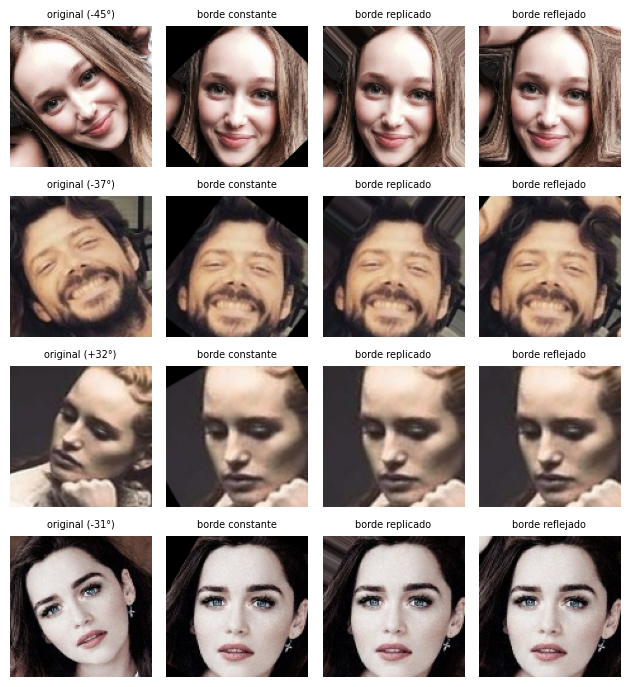

In [22]:
# Las cuatro caras de Pins más inclinadas de la muestra (ángulo entre los ojos), alineadas con cada tipo de borde
TIPOS_BORDE = {"constante": cv2.BORDER_CONSTANT, "replicado": cv2.BORDER_REPLICATE, "reflejado": cv2.BORDER_REFLECT_101}


def alinear_con_borde(img, tipo):
    """Detecta con el borde indicado y devuelve la cara más centrada alineada (AlignedFace) o None."""
    con_borde, _ = agregar_borde(img, tipo)
    cajas = servicio.detect_faces(con_borde)
    return servicio.align_face(con_borde, mas_centrada(cajas, *con_borde.shape[:2])) if cajas else None


def angulo_ojos(alineada):
    """Ángulo en grados de la recta entre los dos ojos en la foto original."""
    (x0, y0), (x1, y1) = alineada.keypoints[0], alineada.keypoints[1]
    return float(np.degrees(np.arctan2(y1 - y0, x1 - x0)))


pins_muestra = filas_borde.query("dataset == 'Pins' and caras_con > 0").copy()
pins_muestra["angulo"] = [angulo_ojos(alinear_con_borde(cv2.imread(r), cv2.BORDER_REFLECT_101)) for r in pins_muestra["ruta"]]
inclinadas = pins_muestra.loc[pins_muestra["angulo"].abs().nlargest(4).index]
imgs, titulos = [], []
for fila in inclinadas.itertuples():
    original = cv2.imread(fila.ruta)
    imgs.append(original); titulos.append(f"original ({fila.angulo:+.0f}°)")
    for nombre, tipo in TIPOS_BORDE.items():
        imgs.append(alinear_con_borde(original, tipo).image); titulos.append(f"borde {nombre}")
grilla(imgs, 4, 4, titulos)

*Figura 5. Las cuatro caras más inclinadas de una muestra de 300 fotos de Pins (a la izquierda, con el ángulo entre los ojos) y su cara alineada después de detectar con un borde constante, replicado y reflejado.*

Con el borde constante, las cuatro caras alineadas tienen triángulos negros en las esquinas (Figura 5): la rotación de `norm_crop` mete el borde adentro del recorte. Con el borde replicado aparecen rayas (la última fila de píxeles estirada), y con el reflejado, una continuación de la foto que casi no se nota. Una CNN entrenada con Pins podría aprender que las esquinas negras indican Pins, una pista que no tiene nada que ver con la identidad y que en LFW no aparece. Por eso se usa el borde reflejado, en los dos datasets.

### Procesamiento de todas las fotos

Entran todas las fotos de Pins y las de LFW menos las de las 15 personas repetidas. Cada foto recibe el borde reflejado y pasa por `detect_faces`, `align_face` y `extract_embedding_from_face`. Por foto se guardan la cantidad de caras, todas las cajas, y para la cara elegida: su caja en coordenadas de la foto original (restando el borde, así que puede salir de la foto si la cara estaba cortada), su lado menor, si hubo puntos para alinear, el foco (varianza del Laplaciano de la cara alineada en gris), el brillo, la cara alineada en PNG y el embedding. Se usa PNG y no JPG porque la CNN entrena sobre estas caras, y otra compresión con pérdida se sumaría a la del JPG original.

Cuando hay más de una cara, hay que elegir cuál es la de la persona etiquetada. Hay dos reglas razonables: la cara más centrada (las fotos de LFW están centradas en la persona) y la más grande. Como todavía no se sabe cuál es mejor, cuando eligen caras distintas se procesan las dos, y la elección se hace después con datos.

El procesamiento se guarda en tandas de 1.000 fotos. Si se corta, al volver a ejecutar la celda se retoma desde la última tanda completa.

In [23]:
def alinear_y_describir(con_borde, caja, p, ruta_png):
    """Alinea la caja con el FaceService, guarda la cara en PNG y devuelve sus datos (en coordenadas de la foto original) y su embedding."""
    alineada = servicio.align_face(con_borde, caja)
    gris = cv2.cvtColor(alineada.image, cv2.COLOR_BGR2GRAY)
    ruta_png.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(ruta_png), alineada.image)
    x1, y1, x2, y2 = caja
    datos = {
        "x1": x1 - p, "y1": y1 - p, "x2": x2 - p, "y2": y2 - p, "lado": min(x2 - x1, y2 - y1),
        "con_landmarks": alineada.keypoints is not None, "foco": cv2.Laplacian(gris, cv2.CV_64F).var(),
        "brillo": gris.mean(), "ruta_alineada": ruta_png.as_posix(),
    }
    return datos, np.array(servicio.extract_embedding_from_face(alineada), dtype=np.float32)


def procesar_foto(fila):
    """Detecta con borde y alinea la cara más centrada y la más grande (una sola vez si son la misma)."""
    con_borde, p = agregar_borde(cv2.imread(fila.ruta))
    cajas = servicio.detect_faces(con_borde)
    resultado = {"n_caras": len(cajas), "cajas": json.dumps([[x1 - p, y1 - p, x2 - p, y2 - p] for x1, y1, x2, y2 in cajas])}
    vacio = np.full(EMBEDDING_DIM, np.nan, dtype=np.float32)
    if not cajas:
        return resultado, vacio, vacio
    base = RUTA_ALINEADAS / fila.dataset / fila.persona / Path(fila.ruta).stem
    centrada, grande = mas_centrada(cajas, *con_borde.shape[:2]), mas_grande(cajas, *con_borde.shape[:2])
    datos, emb_c = alinear_y_describir(con_borde, centrada, p, base.parent / f"{base.name}.png")
    resultado.update({f"{k}_centrada": v for k, v in datos.items()})
    emb_g = emb_c
    if grande != centrada:
        datos, emb_g = alinear_y_describir(con_borde, grande, p, base.parent / f"{base.name}_grande.png")
    resultado.update({f"{k}_grande": v for k, v in datos.items()})
    resultado["reglas_difieren"] = grande != centrada
    return resultado, emb_c, emb_g

In [24]:
# Procesa todas las fotos en tandas de 1.000 y guarda cada tanda en disco (el CSV al final, así que si existe la tanda está completa)
RUTA_DETECCION = RUTA_INTERMEDIOS / "deteccion"
RUTA_ALINEADAS = RUTA_INTERMEDIOS / "alineadas"
RUTA_DETECCION.mkdir(parents=True, exist_ok=True)
TANDA = 1000
entradas = imagenes[~((imagenes["dataset"] == "LFW") & imagenes["persona_norm"].isin(repetidas_norm))].reset_index(drop=True)
tandas = range(0, len(entradas), TANDA)
for k, desde in enumerate(tandas):
    ruta_tanda = RUTA_DETECCION / f"tanda_{k:03d}.csv"
    if ruta_tanda.exists():
        continue
    filas, embs_c, embs_g = [], [], []
    for fila in entradas.iloc[desde:desde + TANDA].itertuples():
        inicio = time.perf_counter()
        resultado, emb_c, emb_g = procesar_foto(fila)
        filas.append({"dataset": fila.dataset, "persona": fila.persona, "ruta": fila.ruta, **resultado, "ms": 1000 * (time.perf_counter() - inicio)})
        embs_c.append(emb_c); embs_g.append(emb_g)
    np.save(RUTA_DETECCION / f"tanda_{k:03d}_centrada.npy", np.stack(embs_c))
    np.save(RUTA_DETECCION / f"tanda_{k:03d}_grande.npy", np.stack(embs_g))
    pd.DataFrame(filas).to_csv(ruta_tanda, index=False)
deteccion = pd.concat([pd.read_csv(RUTA_DETECCION / f"tanda_{k:03d}.csv") for k in range(len(tandas))], ignore_index=True)
emb_centrada = np.concatenate([np.load(RUTA_DETECCION / f"tanda_{k:03d}_centrada.npy") for k in range(len(tandas))])
emb_grande = np.concatenate([np.load(RUTA_DETECCION / f"tanda_{k:03d}_grande.npy") for k in range(len(tandas))])
assert deteccion["ruta"].equals(entradas["ruta"]) and len(emb_centrada) == len(emb_grande) == len(deteccion)
print(f"{len(deteccion)} fotos en {len(tandas)} tandas  |  {deteccion['ms'].sum() / 60000:.1f} min en total  |  mediana {deteccion['ms'].median():.0f} ms por foto en la GPU")

30685 fotos en 31 tandas  |  22.5 min en total  |  mediana 43 ms por foto en la GPU


In [25]:
# Cantidad de caras por foto, fotos sin puntos para alinear y fotos donde las dos reglas eligen caras distintas
deteccion["reglas_difieren"] = deteccion["reglas_difieren"].astype("boolean").fillna(False).astype(bool)
deteccion.groupby("dataset", sort=False).agg(
    fotos=("ruta", "size"),
    sin_cara=("n_caras", lambda n: int((n == 0).sum())),
    una_cara=("n_caras", lambda n: int((n == 1).sum())),
    mas_de_una=("n_caras", lambda n: int((n > 1).sum())),
    sin_landmarks=("con_landmarks_centrada", lambda s: int((s == False).sum())),
    reglas_difieren=("reglas_difieren", "sum"),
)

,fotos,sin_cara,una_cara,mas_de_una,sin_landmarks,reglas_difieren
dataset,,,,,,
Pins,17534,60,17250,224,5,0
LFW,13151,0,10080,3071,0,553


Las 30.685 fotos se procesaron en 22,5 minutos, con una mediana de 43 ms por foto. En Pins, 60 fotos (el 0,34%) quedan sin cara y 224 tienen más de una. En LFW ninguna queda sin cara, y 3.071 (el 23,4%) tienen más de una. Solo 5 caras, todas de Pins, no tuvieron puntos en la segunda detección y quedaron recortadas sin alinear. En Pins, la cara más centrada y la más grande coinciden siempre; en LFW difieren en 553 fotos.

Con el borde reflejado, el detector puede encontrar caras que no están enteras en la foto: una cara que la foto corta en el margen, y que el reflejo completa, o el reflejo de la propia cara. Para medirlo, se calcula qué parte del área de cada caja secundaria (las que no son la más centrada) cae dentro de la foto original.

In [26]:
# Cajas secundarias (las que no son la más centrada) con menos del 50% de su área dentro de la foto original, es decir, mayormente sobre el borde
tamanos = inventario.set_index("ruta")[["alto", "ancho"]]
filas_sec = []
for fila in deteccion.query("n_caras > 1").join(tamanos, on="ruta").itertuples():
    principal = [fila.x1_centrada, fila.y1_centrada, fila.x2_centrada, fila.y2_centrada]
    for x1, y1, x2, y2 in json.loads(fila.cajas):
        if [x1, y1, x2, y2] == principal:
            continue
        dentro = max(0, min(x2, fila.ancho) - max(x1, 0)) * max(0, min(y2, fila.alto) - max(y1, 0)) / ((x2 - x1) * (y2 - y1))
        filas_sec.append({"dataset": fila.dataset, "ruta": fila.ruta, "caja": (x1, y1, x2, y2), "principal": principal, "dentro": dentro})
secundarias = pd.DataFrame(filas_sec)
secundarias["sobre_el_borde"] = secundarias["dentro"] < 0.5
fotos_con_otra_cara = secundarias[~secundarias["sobre_el_borde"]].groupby("dataset")["ruta"].nunique()
secundarias.groupby("dataset", sort=False).agg(
    cajas_secundarias=("ruta", "size"), sobre_el_borde=("sobre_el_borde", "mean"), fotos_con_mas_de_una=("ruta", "nunique"),
).assign(fotos_con_mas_de_una_dentro_de_la_foto=fotos_con_otra_cara).round(3)

,cajas_secundarias,sobre_el_borde,fotos_con_mas_de_una,fotos_con_mas_de_una_dentro_de_la_foto
dataset,,,,
Pins,286,0.612,224,105
LFW,5664,0.414,3071,2530


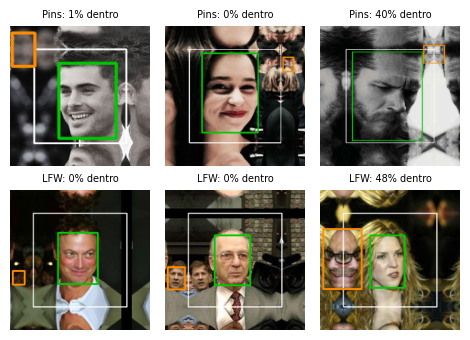

In [27]:
# Seis cajas secundarias sobre el borde (tres por dataset), dibujadas sobre la foto con el borde: en blanco la foto original, en verde la cara principal y en naranja la secundaria
ejemplos_borde = secundarias[secundarias["sobre_el_borde"]].drop_duplicates("ruta").groupby("dataset", sort=False).sample(3, random_state=SEMILLA)
imgs, titulos = [], []
for fila in ejemplos_borde.itertuples():
    img = cv2.imread(fila.ruta)
    con_borde, p = agregar_borde(img)
    cv2.rectangle(con_borde, (p, p), (p + img.shape[1], p + img.shape[0]), (255, 255, 255), 2)
    for caja, color in [(fila.principal, (0, 200, 0)), (fila.caja, (0, 140, 255))]:
        x1, y1, x2, y2 = (int(v) + p for v in caja)
        cv2.rectangle(con_borde, (x1, y1), (x2, y2), color, 3)
    imgs.append(con_borde); titulos.append(f"{fila.dataset}: {100 * fila.dentro:.0f}% dentro")
grilla(imgs, 2, 3, titulos, lado=224)

*Figura 7. Seis cajas secundarias que caen mayormente sobre el borde reflejado (tres de Pins arriba y tres de LFW abajo). El rectángulo blanco marca la foto original, el verde la cara principal y el naranja la caja secundaria, con el porcentaje de su área que queda dentro de la foto.*

El 41,4% de las cajas secundarias de LFW y el 61,2% de las de Pins tienen menos de la mitad de su área dentro de la foto. La Figura 7 muestra de qué se trata: en su mayoría son reflejos de caras chicas del fondo, o caras que la foto corta en el margen y que el reflejo completa (abajo a la derecha, con el 48% de la caja dentro). Contando solo las caras que están mayormente dentro de la foto, las fotos con más de una cara bajan de 3.071 a 2.530 en LFW y de 224 a 105 en Pins. Ese es el costo del borde reflejado: infla la cantidad de caras por foto, así que la regla de calidad de "más de un rostro" no puede usar `n_caras` tal cual. En la elección de la cara principal no influye, porque la persona etiquetada está en el centro y las cajas sobre el borde quedan, por construcción, en la periferia.

### Cara principal

El criterio para elegir la regla se fija antes de mirar el resultado. En cada foto donde las dos reglas eligen caras distintas, se compara cada cara elegida con el centroide de los embeddings de las fotos de **una sola cara** de la misma persona, donde no hay duda de quién es. La regla que elige la cara más parecida a ese centroide en más fotos es la que se usa. Solo entran las personas con al menos una foto de una sola cara. El juez es ArcFace, el mismo modelo que se evalúa en la notebook 2, pero acá solo se usa para decidir cuál de dos caras de la misma foto es la persona etiquetada.

In [28]:
# En las fotos donde las reglas difieren, qué cara se parece más a las fotos de una sola cara de la misma persona
centroides = {}
for clave, grupo in deteccion[deteccion["n_caras"] == 1].groupby(["dataset", "persona"]):
    c = emb_centrada[grupo.index].mean(axis=0)
    centroides[clave] = c / np.linalg.norm(c)
difieren = deteccion[deteccion["reglas_difieren"]]
filas_regla = [
    {"dataset": fila.dataset, "ruta": fila.ruta, "coseno_centrada": float(emb_centrada[i] @ centroides[(fila.dataset, fila.persona)]),
     "coseno_grande": float(emb_grande[i] @ centroides[(fila.dataset, fila.persona)])}
    for i, fila in zip(difieren.index, difieren.itertuples()) if (fila.dataset, fila.persona) in centroides
]
reglas = pd.DataFrame(filas_regla)
reglas["gana"] = np.where(reglas["coseno_centrada"] >= reglas["coseno_grande"], "centrada", "grande")
tabla_reglas = reglas.groupby("dataset", sort=False).agg(
    fotos=("gana", "size"), gana_centrada=("gana", lambda g: (g == "centrada").mean()), gana_grande=("gana", lambda g: (g == "grande").mean()),
    mediana_coseno_centrada=("coseno_centrada", "median"), mediana_coseno_grande=("coseno_grande", "median"),
)
tabla_reglas.loc["total"] = [len(reglas), (reglas["gana"] == "centrada").mean(), (reglas["gana"] == "grande").mean(), reglas["coseno_centrada"].median(), reglas["coseno_grande"].median()]
tabla_reglas.round(3).astype({"fotos": int})

,fotos,gana_centrada,gana_grande,mediana_coseno_centrada,mediana_coseno_grande
dataset,,,,,
LFW,315,0.984,0.016,0.758,0.011
total,315,0.984,0.016,0.758,0.011


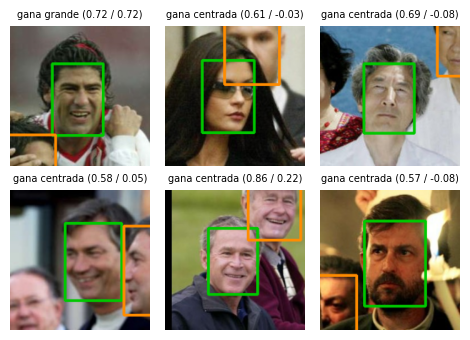

In [29]:
# Seis fotos donde las reglas difieren: en verde la cara más centrada, en naranja la más grande, y en el título la regla que gana
ejemplos_regla = reglas.sample(min(6, len(reglas)), random_state=SEMILLA)
imgs, titulos = [], []
for fila in ejemplos_regla.itertuples():
    datos = deteccion.loc[deteccion["ruta"] == fila.ruta].iloc[0]
    img = cv2.imread(fila.ruta)
    for regla, color in [("centrada", (0, 200, 0)), ("grande", (0, 140, 255))]:
        x1, y1, x2, y2 = (int(datos[f"{c}_{regla}"]) for c in ["x1", "y1", "x2", "y2"])
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 3)
    imgs.append(img); titulos.append(f"gana {fila.gana} ({fila.coseno_centrada:.2f} / {fila.coseno_grande:.2f})")
grilla(imgs, 2, 3, titulos, lado=224)

*Figura 6. Seis fotos al azar en las que la cara más centrada (verde) y la más grande (naranja) son distintas. Entre paréntesis, el coseno de cada una contra el centroide de las fotos de una sola cara de la persona.*

De las 553 fotos de LFW donde las reglas difieren, 315 son de personas que tienen al menos una foto de una sola cara, y entran en la comparación. En el 98,4% de ellas, la cara más centrada es la más parecida al centroide de la persona. La mediana del coseno es 0,758 para la cara más centrada y 0,011 para la más grande, un valor de personas distintas: cuando las reglas difieren, la cara más grande casi siempre es otra persona. La Figura 6 muestra el patrón: la más grande es alguien en primer plano o una caja sobre el borde, y la persona etiquetada está en el centro. Se usa la cara más centrada. En las otras 238 fotos no hay contra qué comparar, y se aplica la misma regla.

In [30]:
# Tabla final con la regla que eligió el criterio: una fila por foto, con su cara alineada y su embedding de ArcFace (Modelo B)
REGLA = tabla_reglas.loc["total", ["gana_centrada", "gana_grande"]].astype(float).idxmax().removeprefix("gana_")
columnas = ["x1", "y1", "x2", "y2", "lado", "con_landmarks", "foco", "brillo", "ruta_alineada"]
caras = deteccion[["dataset", "persona", "ruta", "n_caras", "cajas"]].join(deteccion[[f"{c}_{REGLA}" for c in columnas]].set_axis(columnas, axis=1))
embeddings_arcface = emb_centrada if REGLA == "centrada" else emb_grande
caras.to_csv(RUTA_INTERMEDIOS / "caras.csv", index=False)
np.save(RUTA_INTERMEDIOS / "embeddings_arcface.npy", embeddings_arcface)
print(f"Regla elegida: {REGLA}  |  {len(caras)} fotos, {caras['ruta_alineada'].notna().sum()} con cara alineada  |  embeddings {embeddings_arcface.shape}")

Regla elegida: centrada  |  30685 fotos, 30625 con cara alineada  |  embeddings (30685, 512)


### Antes y después de la alineación

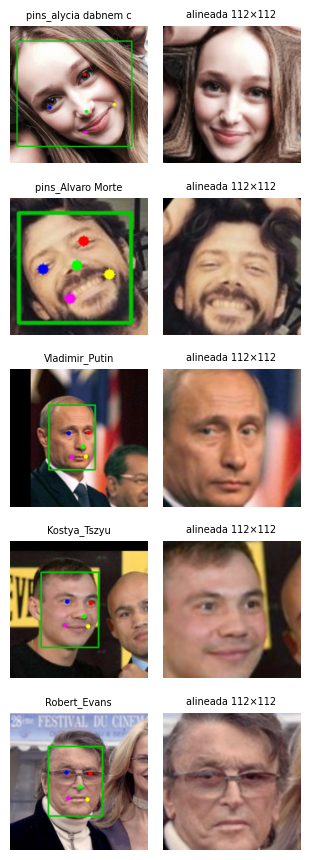

In [31]:
# Foto original con la caja y los cinco puntos, y su cara alineada: dos caras inclinadas de Pins y tres fotos de LFW con más de una cara
ejemplos_alin = list(inclinadas["ruta"].iloc[:2]) + list(caras.query("dataset == 'LFW' and n_caras > 1").sample(3, random_state=SEMILLA)["ruta"])
COLORES_PUNTOS = [(255, 0, 0), (0, 0, 255), (0, 255, 0), (255, 0, 255), (0, 255, 255)]
imgs, titulos = [], []
for ruta in ejemplos_alin:
    img = cv2.imread(ruta)
    con_borde, p = agregar_borde(img)
    cajas = servicio.detect_faces(con_borde)
    caja = (mas_centrada if REGLA == "centrada" else mas_grande)(cajas, *con_borde.shape[:2])
    alineada = servicio.align_face(con_borde, caja)
    dibujo = img.copy()
    x1, y1, x2, y2 = (v - p for v in caja)
    cv2.rectangle(dibujo, (x1, y1), (x2, y2), (0, 200, 0), 2)
    for (kx, ky), color in zip(alineada.keypoints, COLORES_PUNTOS):
        cv2.circle(dibujo, (int(kx + x1), int(ky + y1)), 4, color, -1)
    imgs += [dibujo, alineada.image]; titulos += [Path(ruta).parent.name[:20], "alineada 112×112"]
grilla(imgs, 5, 2, titulos, lado=224)

*Figura 8. Fotos originales con la caja y los cinco puntos (ojo izquierdo en azul, ojo derecho en rojo, nariz en verde y comisuras en magenta y amarillo) y su cara alineada: dos caras inclinadas de Pins y tres fotos de LFW con más de una cara.*

Las caras inclinadas de Pins (−45° y −37°) quedan derechas después de alinear, y en las fotos de LFW con más de una cara se alinea la persona del centro (Figura 8). Los cinco puntos caen sobre los ojos, la nariz y las comisuras, en el orden que espera el frontend de la app.

Formas distintas en la muestra: [(112, 112, 3)]


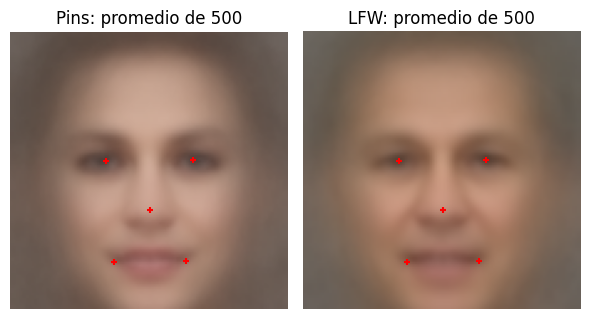

In [32]:
# Si la alineación es consistente, todas las caras miden 112×112 y el promedio de 1.000 de ellas es nítido, con los ojos sobre la plantilla de ArcFace
muestra_alin = caras.dropna(subset=["ruta_alineada"]).groupby("dataset", sort=False).sample(500, random_state=SEMILLA)
alineadas = np.stack([cv2.imread(r) for r in muestra_alin["ruta_alineada"]])
print(f"Formas distintas en la muestra: {sorted({img.shape for img in alineadas})}")
fig, ejes = plt.subplots(1, 2, figsize=(6, 3.4))
for eje, dataset in zip(ejes, ["Pins", "LFW"]):
    del_dataset = alineadas[(muestra_alin["dataset"] == dataset).to_numpy()]
    eje.imshow(cv2.cvtColor(del_dataset.mean(axis=0).astype(np.uint8), cv2.COLOR_BGR2RGB))
    eje.scatter(arcface_dst[:, 0], arcface_dst[:, 1], s=25, c="red", marker="+")
    eje.set_title(f"{dataset}: promedio de {len(del_dataset)}"); eje.axis("off")
plt.tight_layout()
plt.show()

*Figura 9. Promedio de 500 caras alineadas de cada dataset, con los cinco puntos de la plantilla de ArcFace marcados en rojo.*

Todas las caras de la muestra miden 112×112. El promedio de 500 caras de cada dataset es nítido en los ojos, la nariz y la boca, y los cinco puntos de la plantilla de ArcFace caen sobre cada uno (Figura 9). Si la alineación fallara en una parte de las caras, el promedio se vería borroso o con los rasgos duplicados.

In [33]:
# Si los embeddings son los que espera la app, tienen EMBEDDING_DIM dimensiones y norma 1
con_cara = ~np.isnan(embeddings_arcface).any(axis=1)
normas = np.linalg.norm(embeddings_arcface[con_cara], axis=1)
print(f"Dimensión: {embeddings_arcface.shape[1]} (EMBEDDING_DIM = {EMBEDDING_DIM})  |  norma: mínimo {normas.min():.6f}, máximo {normas.max():.6f}  |  fotos sin cara (NaN): {(~con_cara).sum()}")

Dimensión: 512 (EMBEDDING_DIM = 512)  |  norma: mínimo 1.000000, máximo 1.000000  |  fotos sin cara (NaN): 60


Los embeddings tienen las 512 dimensiones de `EMBEDDING_DIM` y norma 1, como los que guarda la app. Las 60 fotos sin cara quedan con `NaN`, para descartarlas en el control de calidad.